# Implementation of a finite element solver, part 1: L²-projection

In [22]:
# Make plotted figures interactive
%matplotlib inline

# If you want interactive figures and ipympl is installed:
# %matplotlib ipympl

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import sympy as sy
import meshtools as mt
import plottools as pt
import tracemalloc
import pandas as pd

## Problem 1. Assembly of the mass matrix

### The local mass matrix on the reference triangle

The nodal basis/shape functions for the first-order Lagrange element $\mathbb{P}_1$ on the unit triangle $\widehat{T}$ are

$$
\begin{aligned}
\lambda_0(\widehat{x},\widehat{y}) &= 1 - \widehat{x} -\widehat{y}
\\
\lambda_1(\widehat{x},\widehat{y}) &= \widehat{x}
\\
\lambda_2(\widehat{x},\widehat{y}) &= \widehat{y}
\end{aligned}
$$

The local mass matrix $\widehat{M}$ on the reference triangle $\widehat{T}$
is defined with entries   

$$
\widehat{M}_{\alpha\beta} = \dfrac{1}{|\widehat{T}|}\int_{\widehat{T}} \lambda_\beta(\widehat{x},\widehat{y}) \lambda_\alpha(\widehat{x},\widehat{y}) \, d\widehat{x} d\widehat{y}, \quad \alpha,\beta = 0,1,2.
$$

so that the local mass matrix on an element $T$ can be computed as

$$
M_T = |T| \cdot \widehat{M}
$$

where $|T|$ is the area of the element $T$. Now compute $\widehat{M}$
using symbolic integration with the `sympy` package. 
<!-- **b)** a **suitable** quadrature rule for the unit triangle $\widehat{T}$ from the list given in the lectures. Justify your choice of quadrature rule and make sure you get the same in both cases (up to machine precision, i.e $\leqslant 10^{-13}$). -->

In [23]:
# Reference mass matrix M_hat via symbolic integration over the unit triangle
x_hat, y_hat = sy.symbols('x_hat y_hat')
lam = [1 - x_hat - y_hat, x_hat, y_hat]   # lambdas
area_ref = sy.Rational(1, 2)              # |T_hat|

M_hat = sy.Matrix(3, 3, lambda a, b: sy.integrate(lam[b] * lam[a],
                                                  (y_hat, 0, 1 - x_hat), (x_hat, 0, 1)) / area_ref)
display(M_hat)

# Check: identical to the M_ref used in the assembly functions below
print(M_hat == sy.Matrix([[2, 1, 1], [1, 2, 1], [1, 1, 2]]) / 12)

Matrix([
[ 1/6, 1/12, 1/12],
[1/12,  1/6, 1/12],
[1/12, 1/12,  1/6]])

True


### Assembly of the global mass matrix 

Next, you are asked to implement three different variants of the assembly of the global mass matrix $M$ in Python, and to benchmark their memory usage and execution time. 

The first version should use a dense matrix representation using standard NumPy arrays, the second version should use a sparse matrix representation in DOK format, and the third version should use a sparse matrix representation in COO format.

For all three variants, use the function signature

```python
def assemble_mass_matrix_MATRIX_CLASS(P, C):
    """Assemble the P1 mass matrix on the triangulation (P, C).

    P : (N_p, 2) array, coordinates of the mesh vertices (point matrix).
    C : (N_t, 3) integer array, vertex indices of each triangle (connectivity matrix).

    Returns the (N_p, N_p) mass matrix M, stored as MATRIX_CLASS.
    """
    ...
    return M
```

where `MATRIX_CLASS` is either `dense`, `dok`, or `coo`.

To measure the memory usage, you can use the following function as a starting point:

In [24]:
def memit(f, *args, **kwargs):
    """Call f(*args, **kwargs) and measure the memory it allocated.

    Uses tracemalloc to track the memory allocated by Python (including NumPy
    and SciPy arrays) during the call and returns two numbers in MB:

    kept : memory still allocated when f returns (essentially the result).
    peak : maximum memory allocated at any time during the call,
           including temporary arrays that were freed again.

    Returns (result, kept, peak), where result is the return value of f.
    """
    tracemalloc.start()
    result = f(*args, **kwargs)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return result, current/1e6, peak/1e6

To print the memory usage of the assembly functions, you can simply type

```python
M = memit(assemble_mass_matrix_dense, P, C)
```

Feel free to modify the function to suit your needs, e.g. if you want to return the measurement as a tuple of (kept, peak) values.

For the execution time, you can use the `%timeit` and `%%timeit` magic functions in IPython,
see [corresponding documentation](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-timeit).

In a nutshell, `%%timeit` measures the execution time of an entire cell, while `%timeit`
only measures the execution time of a single line, e.g. as in

```python
%timeit my_function()
```
__Regarding the usage of `timeit`:__
To obtain reliable timings, `timeit` does not perform a single run, but
rather a number of runs `R`, and in each run, the given statement is executed
`N` times in a loop. This can sometimes lead to long waiting times, so you can set `R` and `N` yourself:
```python
%timeit -r <R> -n <N> my_function()
```
You can also store the timing results by passing the option `-o`:

```python
timings_data = %timeit -o my_function()
```
    
which stores the data from the timing experiment. You can access the best time measured
in seconds by
```python
timings_data.best
```

With these preparations, let us get started!

**a)** Implement the assembly of the mass matrix using a dense, DOK and COO matrix representation. 

For the first one you can use the following code outline:

In [25]:
def assemble_mass_matrix_dense(P, C):
    """Assemble the P1 mass matrix as a dense NumPy array.

    P : (N_p, 2) array, coordinates of the mesh vertices (point matrix).
    C : (N_t, 3) integer array, vertex indices of each triangle (connectivity matrix).

    Returns the (N_p, N_p) mass matrix M as a dense np.ndarray, assembled
    element by element by adding |T_k| * M_ref into the rows and columns C[k].
    """
    
    # Define constant part M_ref here

    M_ref = np.array([[2,1,1],[1,2,1],[1,1,2]]) / 12
    
    # Deduce number of unknowns from dimensions/shape of P
    n_p = P.shape[0]
    # Deduce number of elements from dimensions of C
    n_t = C.shape[0]
    
    # Create full (dense) matrix M
    M = np.zeros((n_p, n_p))
    
    for T in range(n_t):

        # Get local to global map from C
        l2g = C[T]
        
        # Get triangle nodes from P
        nodes = P[l2g]

        # Unpack nodes into N0,N1,N2
        N0 = nodes[0]
        N1 = nodes[1]
        N2 = nodes[2]

        # Compute area of T
        area = 0.5 * abs((N1[0]-N0[0])*(N2[1]-N0[1]) - (N2[0]-N0[0])*(N1[1]-N0[1]))
        
        # Use area and M_ref to compute M_T
        M_T = area * M_ref
        
        # Instead of 2 loops we can slice out the blocks which
        # correspond to the entries in l2g by using the funny
        # function ix_ in numpy
        M[np.ix_(l2g, l2g)] += M_T
    
    return M



**Debugging/testing hints**: You can compute the mass matrix manually for a small mesh,
e.g. with $N=1$ using the `unitsquare_mesh` function from the `meshtools.py` file, which gives you a mesh with 2 elements, or use the more flexible
`rectangle_mesh` function, where you can specify the number of elements in the $x$ and $y$ directions, e.g. with $N_x=2$ and $N_y=1$, which will produce a mesh with 4 elements.

Now implement the `dok` matrix variant. 

**Hint.** In principle, you only have to change one line compared to the dense matrix variant :)

In [26]:
def assemble_mass_matrix_dok(P, C):
    # Define constant part M_ref here
    M_ref = np.array([[2,1,1],[1,2,1],[1,1,2]]) / 12
    
    # Deduce number of unknowns from dimensions/shape of P
    n_p = P.shape[0]
    # Deduce number of elements from dimensions of C
    n_t = C.shape[0]
    
    M = sp.dok_matrix((n_p, n_p))
    
    for T in range(n_t):

        # Get local to global map from C
        l2g = C[T]
        
        # Get triangle nodes from P
        nodes = P[l2g]

        # Unpack nodes into N0,N1,N2
        N0 = nodes[0]
        N1 = nodes[1]
        N2 = nodes[2]

        # Compute area of T
        area = 0.5 * abs((N1[0]-N0[0])*(N2[1]-N0[1]) - (N2[0]-N0[0])*(N1[1]-N0[1]))
        
        # Use area and M_ref to compute M_T
        M_T = area * M_ref

        for alpha in [0, 1, 2]:
            for beta in [0, 1, 2]:
                M[l2g[alpha], l2g[beta]] += M_T[alpha, beta]
    
    return M


Finally, implement the `coo` matrix variant. Here, try to
avoid the use of a Python for-loop, and rather use vectorized operations from NumPy. 

**Debugging tip.** Since the implementation of the `coo` matrix variant deviates quite a bit from the other two variants, it might
be a good idea to check whether you get the same matrix for all three variants, up to machine precision.

In [27]:
def assemble_mass_matrix_coo(P, C):
    # Define local mass matrix on reference element
    M_ref = 1.0/12.0*np.array([[2, 1, 1],[1, 2, 1],[1, 1, 2]])
    
    # Compute e1 and e2 and area for all triangles at once
    e1 = P[C[:,1]] - P[C[:,0]]
    e2 = P[C[:,2]] - P[C[:,0]]
    area = 0.5 * abs(e1[:,0]*e2[:,1] - e1[:,1]*e2[:,0])
    
    # Create rows, cols, data for the sparse matrix in COO format 
    # You can create rows and cols by repeating and tiling the triangle indices in C
    rows = np.repeat(C, 3, axis=1).ravel()
    cols = np.tile(C, (1,3)).ravel()
    
    # Compute the values for the sparse matrix in COO format by multiplying the area of each triangle with M_ref.
    vals = (area[:, None, None] * M_ref).ravel()
    
    # Create sparse matrix M in COO format and return it
    n_p = P.shape[0]
    M = sp.coo_matrix((vals, (rows, cols)), shape=(n_p, n_p))

    return M


**b)** Benchmark the **memory usage** for each of the three implementations
by assembling the mass matrix for a unit square mesh generated
with `unitsquare_mesh` function for $N=5, 10, 20, 40, 80, 160$.
(If you don't have enough memory, you can skip the last value of $N$.)

Report and compare the results, and explain the results as well as you can.



In [28]:
N_vals = [5, 10, 20, 40, 80, 160]
methods = {"dense": assemble_mass_matrix_dense,
           "DOK": assemble_mass_matrix_dok,
           "COO": assemble_mass_matrix_coo}

rows = []
for N in N_vals:
    P, C = mt.unitsquare_mesh(N)
    row = {"N": N, "N_p": P.shape[0]}
    for name, assemble in methods.items():
        kept, peak = memit(assemble, P, C)[1:]   # drop the matrix right away
        row[f"{name} kept [MB]"] = kept
        row[f"{name} peak [MB]"] = peak
    rows.append(row)

mem_table = pd.DataFrame(rows)
display(mem_table.round(3))

,N,N_p,dense kept [MB],dense peak [MB],DOK kept [MB],DOK peak [MB],COO kept [MB],COO peak [MB]
0,5,36,0.010,0.015,0.015,0.020,0.008,0.019
1,10,121,0.117,0.122,0.056,0.073,0.030,0.068
2,20,441,1.556,1.561,0.401,0.456,0.116,0.265
3,40,1681,22.606,22.611,2.008,2.229,0.462,0.722
4,80,6561,344.374,344.379,8.927,10.010,1.844,2.489
5,160,25921,5375.186,5375.191,36.225,40.692,7.374,9.554


#### Little discussion:

The dense matrix needs by far the most memory. It stores all $N_p^2$ entries so its memory grows like $N_p^2$, i.e. about 16 times per doubling of $N$. At $N=160$ this is $25921^2 \cdot 8$ B $\approx 5.4$ GB, as measured, even though almost all entries are zero.

The sparse formats only store the entries that are actually assembled, so their memory grows like $N_p$, i.e. about 4 times per doubling of $N$. COO stores the 9 contributions of each triangle as (row, column, value) triplets of 16 bytes without summing duplicates, $9 N_t \cdot 16$ B $\approx 7.4$ MB at $N=160$. DOK stores each non-zero only once, but as an entry in a Python dictionary, which costs roughly 200 bytes per entry, so it ends up about 5 times larger than COO.

Kept and peak memory are almost equal for dense and DOK. For COO the peak is higher because of the temporary arrays (areas, indices, values) created during the vectorized assembly.

**c)** Benchmark the **execution time** for each of the three implementations
by assembling the mass matrix for a unit square mesh generated
with `unitsquare_mesh` function for $N=5, 10, 20, 40, 80, 160$.
(If you don't have enough memory, you can skip the last one or two values of $N$.)

Report and compare the results, and explain the results as well as you can.


In [29]:
N_vals = [5, 10, 20, 40, 80, 160]
methods = {"dense": assemble_mass_matrix_dense,
           "DOK": assemble_mass_matrix_dok,
           "COO": assemble_mass_matrix_coo}

rows = []
for N in N_vals:
    P, C = mt.unitsquare_mesh(N)
    row = {"N": N, "N_t": C.shape[0]}
    for name, assemble in methods.items():
        # Best of 3 runs; timeit chooses the number of loops per run itself
        t = %timeit -o -q -r 3 assemble(P, C)
        row[f"{name} [ms]"] = 1e3 * t.best
    rows.append(row)

time_table = pd.DataFrame(rows)
display(time_table.round(3))

,N,N_t,dense [ms],DOK [ms],COO [ms]
0,5,50,0.764,4.573,0.067
1,10,200,3.240,19.059,0.084
2,20,800,11.916,75.037,0.170
3,40,3200,47.646,296.323,0.520
4,80,12800,186.504,1149.242,1.617
5,160,51200,790.386,4854.081,12.097


#### Little discussion:

For all three variants the work per triangle is constant, so the time grows like the number of triangles $N_t = 2N^2$, i.e. by about a factor 4 per doubling of $N$. Only COO grows more slowly on the smallest meshes, where its run time is so short that fixed overheads dominate. The difference between the variants lies in the constant:

* Dense and DOK both loop over the triangles in Python. DOK is about 6 times slower than dense, because each of the 9 updates per triangle is a separate dictionary access through SciPy, while the dense variant adds the whole $3 \times 3$ block with one NumPy operation.
* COO has no Python loop: all triangles are handled at once by vectorized NumPy operations, which makes it about 100 times faster than dense and several hundred times faster than DOK on the larger meshes.


## Problem 2. Quadrature rules

For each degree $d \in \{1,2,3,4\}$, implement one quadrature rule for the unit triangle $\widehat{T}$ from the list given in the lectures.
If several quadrature rules are available for a given degree, give a short justification of your choice.

Check your implementation by verifying that the quadrature rule integrates polynomials of degree $d$ exactly (i.e. up to machine precision error of $10^{-13}$),
and that it does not integrate polynomials of degree $d+1$ exactly.

Throughout this project, we use the convention that the quadrature weights sum to 1, so that
$\int_{\widehat{T}} g \, d\widehat{x} \approx |\widehat{T}| \sum_{q=1}^{n_q} w_q \, g(\widehat{\boldsymbol{x}}_q)$.
If you take a rule from a table where the weights sum to $|\widehat{T}| = 1/2$, rescale the weights accordingly.


In [30]:
def vertex_rule():
    xq = np.array([[0, 0], [1, 0], [0, 1]])
    wq = np.full(3, 1/3)
    return xq, wq

def edge_midpoint_rule():
    xq = np.array([[1/2, 0], [1/2, 1/2], [0, 1/2]])
    wq = np.full(3, 1/3)
    return xq, wq

def four_point_rule():
    L = [[1/3, 1/3, 1/3], 
         [0.6, 0.2, 0.2],
         [0.2, 0.6, 0.2],
         [0.2, 0.2, 0.6]]

    xq = L @ np.array([[0,0], [1,0], [0,1]])

    wq = np.array([-9/16, 25/48, 25/48, 25/48])

    return xq, wq

def six_point_rule():
    a = [0.445948490915965, 0.091576213509771]
    w = [0.223381589678011, 0.109951743655322]

    L = []
    wq = []

    for wi, ai in zip(w, a):
        b = 1 - 2*ai
        L += [[ai, ai, b], [ai, b, ai], [b, ai, ai]]
        wq += [wi] * 3

    L = np.array(L)
    wq = np.array(wq)

    xq = L @ np.array([[0,0], [1,0], [0,1]])

    return xq, wq

def quadrature_rule(d):

    match d:
        case 1:
            return vertex_rule()
        case 2:
            return edge_midpoint_rule()
        case 3:
            return four_point_rule()
        case 4:
            return six_point_rule()
        case _:
            raise ValueError("Quadrature rule only supports d in {1,2,3,4}")


In [31]:
from math import factorial

def exact_monomial_integral(i, j):
    """Exact integral of x^i y^j over the reference triangle."""
    return factorial(i) * factorial(j) / factorial(i + j + 2)

def max_quadrature_error(xq, wq, p):
    """Largest quadrature error over all monomials x^i y^j of total degree p (|T_hat| = 1/2)."""
    return max(abs(0.5 * np.sum(wq * xq[:, 0]**i * xq[:, 1]**(p - i)) - exact_monomial_integral(i, p - i))
               for i in range(p + 1))

tol = 1e-13
quad_rows = []
for d in [1, 2, 3, 4]:
    xq, wq = quadrature_rule(d)
    err_upto_d = max(max_quadrature_error(xq, wq, p) for p in range(d + 1))   # degrees 0, ..., d
    err_next = max_quadrature_error(xq, wq, d + 1)                           # degree d + 1
    quad_rows.append({"d": d, "n_q": len(wq),
                      "max error, degree <= d": err_upto_d, "exact for degree <= d": err_upto_d <= tol,
                      "max error, degree d+1": err_next, "not exact for degree d+1": err_next > tol})

display(pd.DataFrame(quad_rows))

,d,n_q,"max error, degree <= d",exact for degree <= d,"max error, degree d+1",not exact for degree d+1
0,1,3,0.000000e+00,True,0.083333,True
1,2,3,0.000000e+00,True,0.008333,True
2,3,4,2.775558e-17,True,0.002222,True
3,4,6,4.996004e-16,True,0.000126,True


### Choice of quadrature rule:

* **Degree 1: vertex rule** (instead of the centroid rule). It evaluates $f$ only at the vertices of $T$, i.e. at the mesh nodes, so the element load vector is simply $\frac{|T|}{3}\big(f(N_0), f(N_1), f(N_2)\big)$.
* **Degree 2: edge midpoint rule** (instead of the interior three-point rule). Both use three points with equal positive weights, so they cost the same; we chose the edge midpoints since their coordinates are the simplest.
* **Degree 3: four-point rule** (instead of the seven-point rule). It needs the fewest points for degree 3. Its drawback is the negative weight $-\frac{9}{16}$: a positive integrand can give a negative result, and rounding errors are amplified since $\sum_q |w_q| = \frac{17}{8} > 1$. We only use this rule for testing, so we accepted this for the lower cost; otherwise the seven-point rule with only positive weights would be the safer choice.
* **Degree 4: six-point rule**, the only degree-4 rule in the list.


## Problem 3. Assembly of the load vector

Recall that the load vector $\boldsymbol{b} = (b_i)_{i=1}^{n_{\mathrm{sh}}}$ is given by  

$$
b_i = \int_\Omega f(x,y) \phi_i(x,y)\, dx dy
$$

where $\{\phi_i(x,y)\}_{i=1}^{n_{\mathrm{sh}}} $ are the basis functions of the finite element space $V_h = \mathbb{P}_1^c(\mathcal{T}_h)$.

Implement a function that assembles the load vector $\boldsymbol{b}$
by completing the code snippet below.

In [32]:
def assemble_load_vector(f, P, C, xq, wq):
    """Assemble the P1 load vector b_i = int f phi_i dx using quadrature.

    f      : function f(x, y), vectorized over NumPy arrays x and y.
    P      : (N_p, 2) array, coordinates of the mesh vertices (point matrix).
    C      : (N_t, 3) integer array, vertex indices of each triangle (connectivity matrix).
    xq, wq : quadrature points (n_q, 2) and weights (n_q,) on the reference
             triangle, with the weights summing to 1.

    Returns the load vector b as a NumPy array of length N_p.
    """
    # Define constant part here: values of the barycentric coordinates
    # lambda_0 = 1 - x - y, lambda_1 = x, lambda_2 = y at the quadrature points
    barycentric = np.column_stack((1 - xq[:, 0] - xq[:, 1], xq[:, 0], xq[:, 1]))
    L_ref = (wq[:, None] * barycentric).T

    # Deduce number of unknowns from dimensions/shape of P
    n_p = P.shape[0]
    # Deduce number of elements from dimensions of C
    n_t = C.shape[0]
    
    # Create load vector b
    b = np.zeros(n_p)

    for T in range(n_t):
        
        # Get local to global map from C
        l2g = C[T]
        # Get triangle nodes from P
        nodes = P[l2g]
        
        # Unpack nodes into N0,N1,N2
        N0 = nodes[0]
        N1 = nodes[1]
        N2 = nodes[2]
        # Compute area of T
        area = 0.5 * abs((N1[0]-N0[0])*(N2[1]-N0[1]) - (N2[0]-N0[0])*(N1[1]-N0[1]))
    
        # Map the quadrature points to T: row q is sum_beta lambda_beta(xq_q) * N_beta
        xq_T = barycentric @ nodes

        # Evaluate f at the mapped quadrature points
        f_q = f(xq_T[:, 0], xq_T[:, 1])

        # Local load vector b_T[alpha] = |T| sum_q w_q lambda_alpha(xq_q) f(F_T(xq_q))
        b_T = area * (L_ref @ f_q)

        # Add the local contributions to the global load vector
        b[l2g] += b_T

    return b


**Testing/Debugging tips:**

You can test your implementation as follows:
  * If $f = 1$, then the sum of the entries of the load vector $\boldsymbol{b}$ should be equal to the area of the domain $\Omega$, up to a machine precision error of $10^{-13}$. Why?
  * If $f \in \mathbb{P}_1^c(\mathcal{T}_h)$, and you choose a suitable quadrature rule, then $\boldsymbol{b} = M \boldsymbol{f}_I$, where $\boldsymbol{f}_I$ is the vector of nodal values of $f$ at the mesh vertices. Why is this the case, and which order of quadrature rule is suitable?


In [33]:
# Test 1: f = 1            ->  sum(b) = |Omega| = 1
# Test 2: f = 1 + x + y in P1 ->  b = M f_I, if the rule is exact for degree 2
P, C = mt.unitsquare_mesh(10)
M = assemble_mass_matrix_coo(P, C).tocsr()
f_one = lambda x, y: np.ones_like(x)
f_lin = lambda x, y: 1 + x + y
f_lin_I = f_lin(P[:, 0], P[:, 1])

for d in [1, 2, 3, 4]:
    xq, wq = quadrature_rule(d)
    err_sum = abs(assemble_load_vector(f_one, P, C, xq, wq).sum() - 1)
    err_Mf = np.max(np.abs(assemble_load_vector(f_lin, P, C, xq, wq) - M @ f_lin_I))
    print(f"degree {d}: |sum(b) - 1| = {err_sum:.1e},  max|b - M f_I| = {err_Mf:.1e}")

degree 1: |sum(b) - 1| = 1.1e-16,  max|b - M f_I| = 2.5e-04
degree 2: |sum(b) - 1| = 1.1e-16,  max|b - M f_I| = 1.4e-17
degree 3: |sum(b) - 1| = 2.2e-16,  max|b - M f_I| = 1.4e-17
degree 4: |sum(b) - 1| = 1.0e-15,  max|b - M f_I| = 3.5e-17


**Answers to the testing questions:**

* **$f = 1$:** The hat functions sum to one, $\sum_i \phi_i = 1$ on $\Omega$, so $\sum_i b_i = \int_\Omega \sum_i \phi_i \, dx = \int_\Omega 1 \, dx = |\Omega|$. For $f = 1$ the integrand $\phi_i$ is linear, so every rule of degree $\geq 1$ computes each $b_i$ exactly, and the sum equals $|\Omega|$ up to rounding.
* **$f \in \mathbb{P}_1^c(\mathcal{T}_h)$:** Then $f = \sum_j f(N_j) \phi_j$ exactly, so $b_i = \sum_j f(N_j) \int_\Omega \phi_j \phi_i \, dx = (M \boldsymbol{f}_I)_i$. On each triangle the integrand $f \phi_i$ is quadratic, so this only holds if the rule is exact for degree 2. The output above confirms it: the degree-1 rule is off by about $2.5 \cdot 10^{-4}$, while the rules of degree 2 to 4 agree up to machine precision.


## Problem 4. The $L^2$ projection

Recall that the $L^2$ projection $P_h f \in V_h = \mathbb{P}_1^c(\mathcal{T}_h)$ of a function $f$ is defined by

$$
\int_\Omega P_h f \, v \, dx = \int_\Omega f \, v \, dx \quad \forall\, v \in V_h .
$$

Writing $P_h f = \sum_{j=1}^{n_{\mathrm{sh}}} u_j \phi_j$ and testing with $v = \phi_i$ leads to the linear system

$$
M \boldsymbol{u} = \boldsymbol{b},
$$

where $M$ is the mass matrix from Problem 1 and $\boldsymbol{b}$ is the load vector from Problem 3.
The solution vector $\boldsymbol{u}$ contains the values of $P_h f$ at the mesh vertices.


### Task 1. Computing the $L^2$ projection

Write a function that computes the coefficient vector $\boldsymbol{u}$ of $P_h f$ for a given function $f$ and a given mesh $(P, C)$.
Reuse your assembly routines for the mass matrix and the load vector, and solve the linear system with `spsolve` from `scipy.sparse.linalg`.
Note that `spsolve` expects the matrix in CSR or CSC format, so convert your mass matrix with `.tocsr()` if necessary.

To assemble the load vector, use two different quadrature rules from Problem 2:
one that is exact for polynomials of degree 1, and one that is exact for polynomials of degree 2.

**a)** Compute $P_h f$ for the functions

1. $f(x,y) = 1$,
2. $f(x,y) = 1 + x + y$,

on the unit square mesh generated by `unitsquare_mesh` with $N = 10$, using both quadrature rules.
Compare the vector $\boldsymbol{u}$ with the vector $\boldsymbol{f}_I$ of nodal values of $f$ by computing $\max_i |u_i - f(\boldsymbol{x}_i)|$.

* What do you expect $P_h f$ to be for functions $f \in V_h$, and why?
* Which of the four computations reproduce $f$ up to machine precision? Explain your observations
  using the degree of the integrand $f \phi_i$ in the load vector.


In [34]:
f1 = lambda x, y : np.ones_like(x)
f2 = lambda x, y : 1 + x + y

P, C = mt.unitsquare_mesh(10)

M = assemble_mass_matrix_coo(P, C).tocsr()

table = []

for d in [1,2,3,4]:
    
    xq, wq = quadrature_rule(d)

    b1 = assemble_load_vector(f1, P, C, xq, wq)
    b2 = assemble_load_vector(f2, P, C, xq, wq)

    u1 = spsolve(M, b1)
    u2 = spsolve(M, b2)

    f1I = f1(P[:, 0], P[:, 1])
    f2I = f2(P[:, 0], P[:, 1])

    err1 = np.max(np.abs(u1 - f1I))
    err2 = np.max(np.abs(u2 - f2I))

    table.append([err1, err2])

# Pretty-print: max_i |u_i - f(x_i)|, N = 10
tol = 1e-13
print(f"{'quad. degree':>12} | {'f = 1':>18} | {'f = 1 + x + y':>18}")
print("-" * 13 + "+" + "-" * 20 + "+" + "-" * 20)
for d, (e1, e2) in zip([1, 2, 3, 4], table):
    c1 = f"{e1:.2e} {'ok' if e1 < tol else 'X':>2}"
    c2 = f"{e2:.2e} {'ok' if e2 < tol else 'X':>2}"
    print(f"{d:>12} | {c1:>18} | {c2:>18}")


quad. degree |              f = 1 |      f = 1 + x + y
-------------+--------------------+--------------------
           1 |        1.11e-15 ok |        1.69e-01  X
           2 |        1.11e-15 ok |        4.44e-15 ok
           3 |        2.00e-15 ok |        4.44e-15 ok
           4 |        1.78e-15 ok |        6.22e-15 ok


#### Little discussion:

For $f \in V_h$ we expect $P_h f = f$: the $L^2$ projection is the best approximation of $f$ in $V_h$ in the $L^2$ norm, and if $f$ already lies in $V_h$, that is $f$ itself. Since a function in $V_h$ is given by its nodal values, this means $\boldsymbol{u} = \boldsymbol{f}_I$.

Both functions lie in $V_h$, but this is only reproduced if the load vector is computed exactly. For $f = 1$ the integrand $f \phi_i = \phi_i$ is linear on each triangle, so both rules integrate it exactly and both computations reproduce $f$ up to machine precision. For $f = 1 + x + y$ the integrand $f \phi_i$ is quadratic: the degree-2 rule is still exact and reproduces $f$, while the degree-1 rule is not and gives an error of order $10^{-1}$. So three of the four computations reproduce $f$ (the degree-3 and degree-4 rules in the table behave like the degree-2 rule).


**b)** Now consider the function

$$
f(x,y) = \sin(2 \pi x) \cos(\pi y).
$$

Compute $P_h f$ on the unit square meshes generated by `unitsquare_mesh` with $N = 10, 20, 40, 80$, again with both quadrature rules.
For each value of $N$, plot $f$, $P_h f$ and their difference $f - P_h f$.
You can use the function `plot_comparison_2D` from `plottools.py`, which shows all three functions in one figure.
Evaluate $f$ at the mesh vertices to plot it.

* Do you observe convergence in the "eyeball norm"?
* By roughly which factor does the size of the difference $f - P_h f$ decrease each time $N$ is doubled?
  Which convergence rate in $h$ does this suggest?
* Does the choice of quadrature rule for the load vector affect what you see?


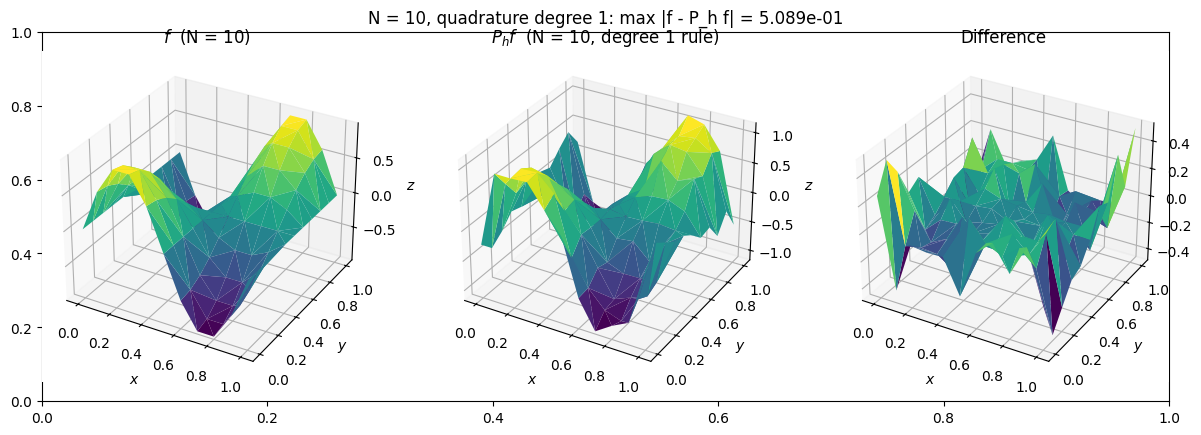

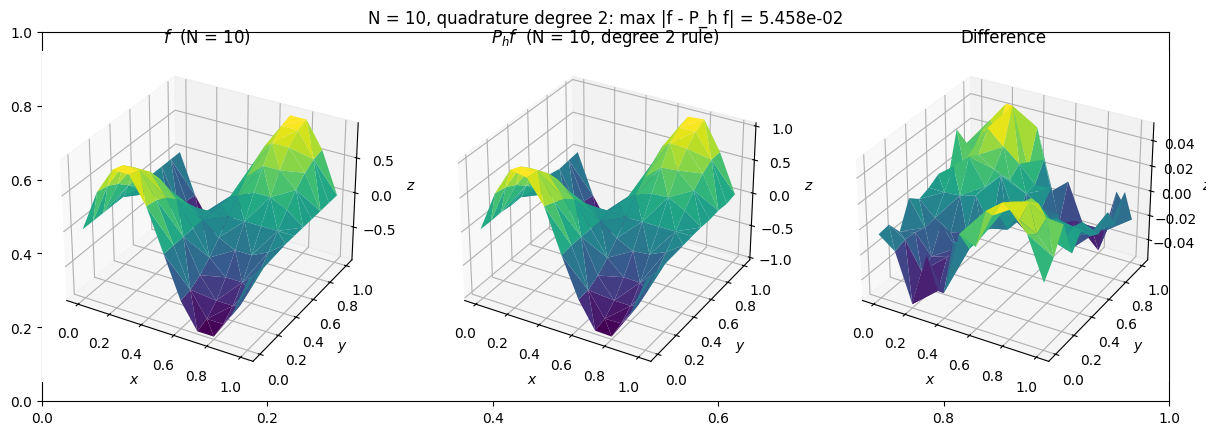

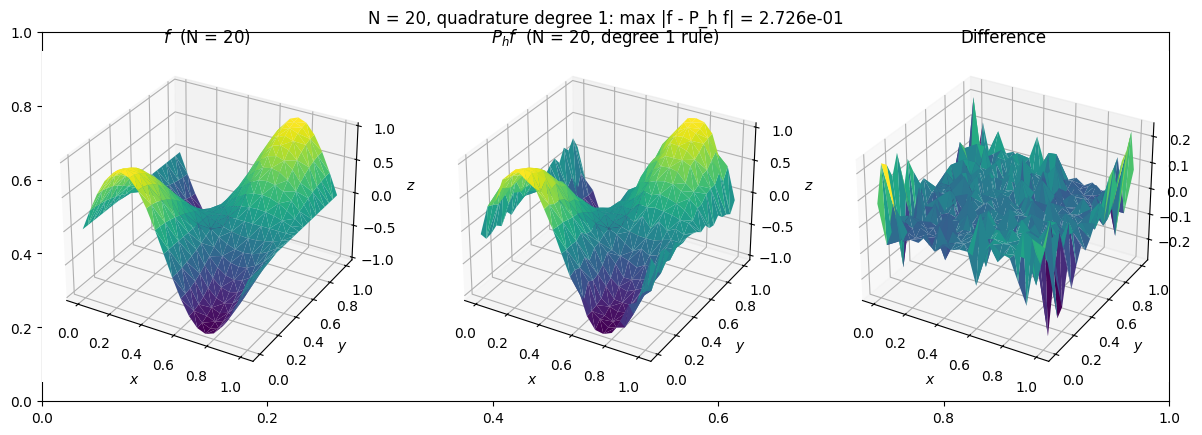

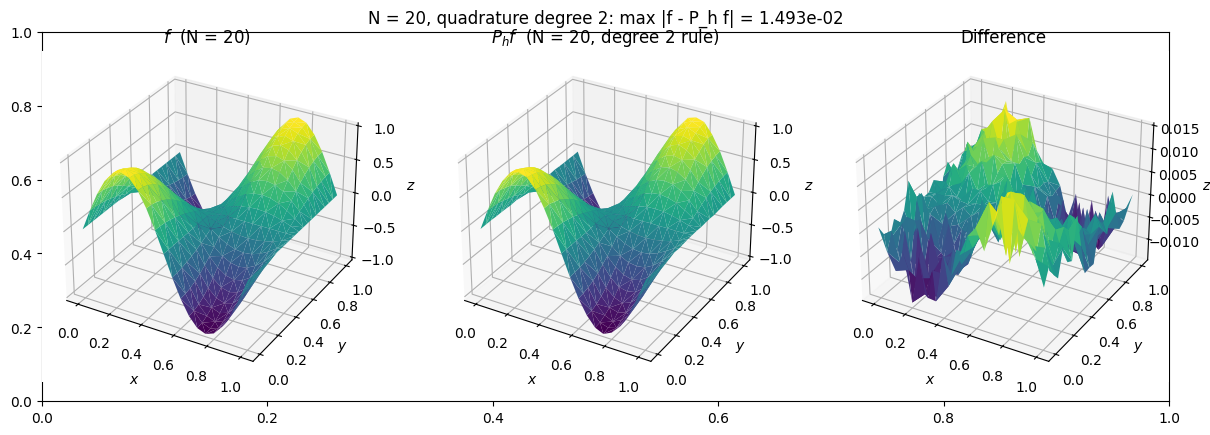

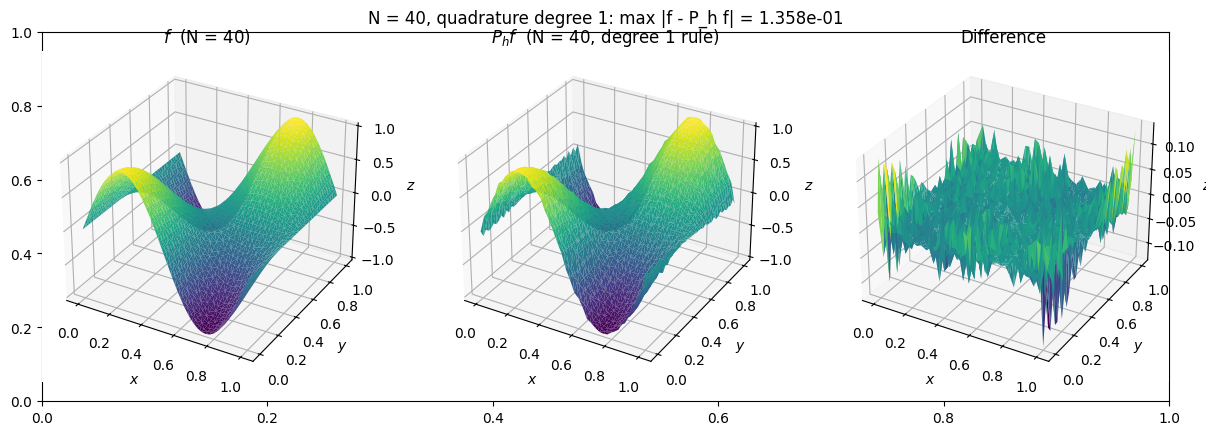

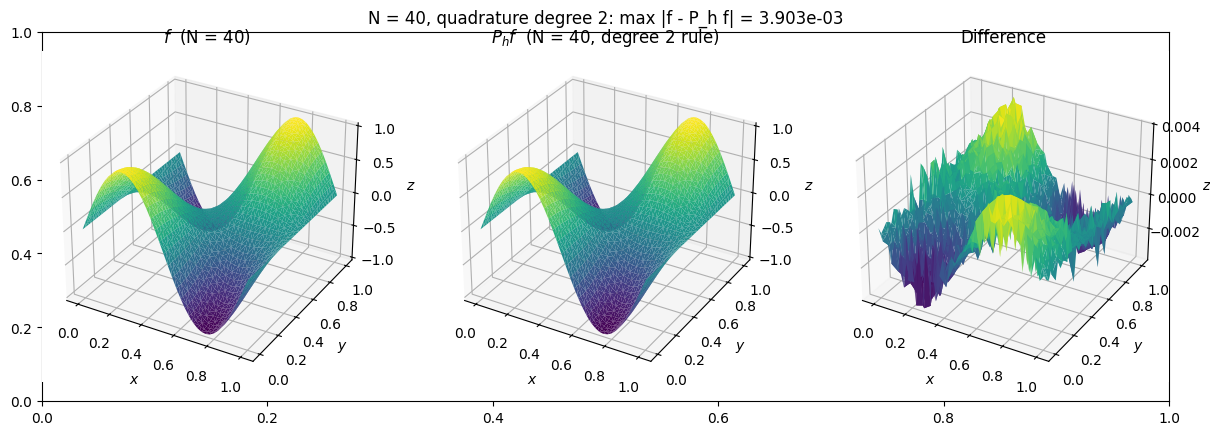

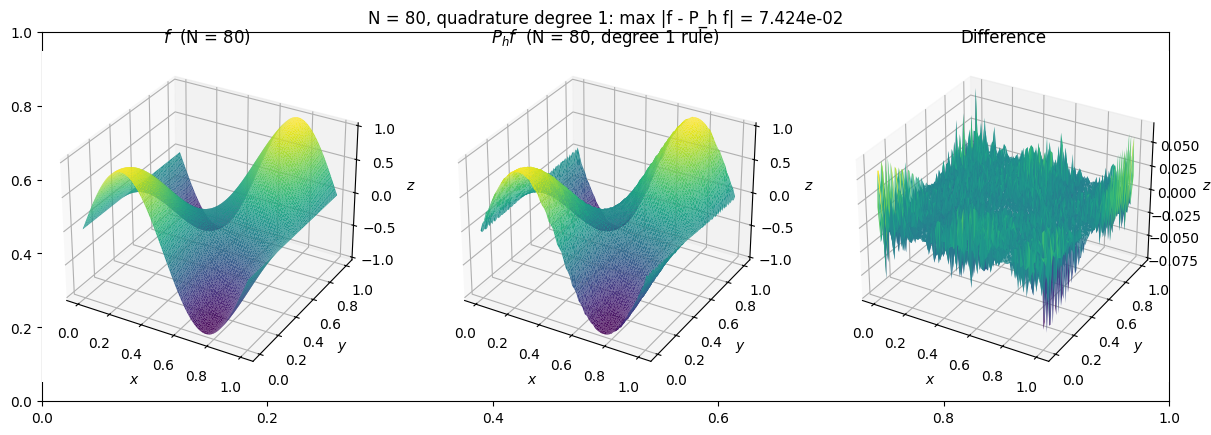

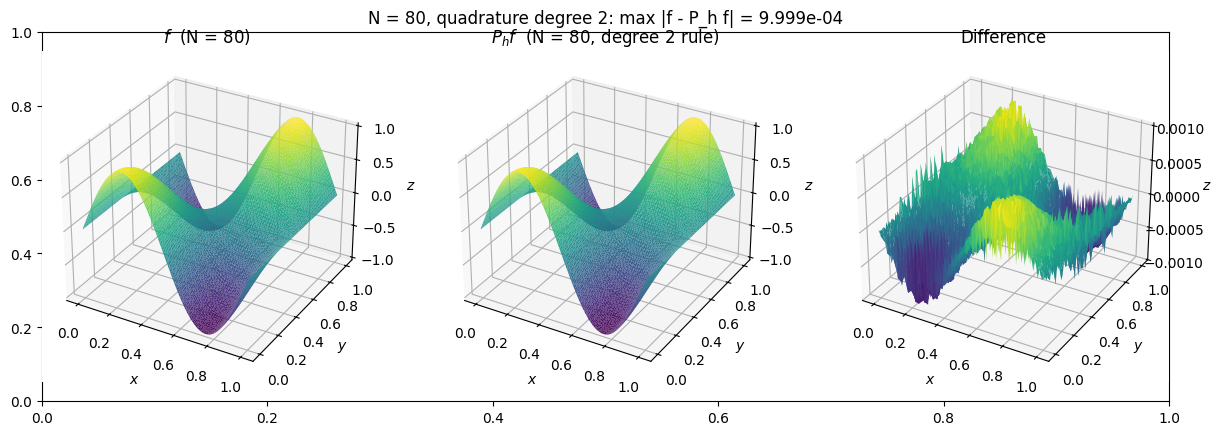

In [35]:
def l2_projection(f, P, C, xq, wq):
    """Coefficient vector u of the L2 projection P_h f, solving M u = b."""
    M = assemble_mass_matrix_coo(P, C).tocsr()
    b = assemble_load_vector(f, P, C, xq, wq)
    return spsolve(M, b)

f = lambda x, y : np.sin(2*np.pi*x) * np.cos(np.pi*y)

N_vals = [10, 20, 40, 80]

for N in N_vals:
    P, C = mt.unitsquare_mesh(N)
    X, Y = P[:, 0], P[:, 1]
    fI = f(X, Y)

    for d in [1, 2]:
        xq, wq = quadrature_rule(d)
        u = l2_projection(f, P, C, xq, wq)

        pt.plot_comparison_2D(X, Y, fI, u, C, 
                              main_title=f"N = {N}, quadrature degree {d}: max |f - P_h f| = {np.max(np.abs(fI - u)):.3e}",
                              title_f1=f"$f$  (N = {N})", title_f2=f"$P_h f$  (N = {N}, degree {d} rule)")


#### Little discussion:

Yes, for both rules $P_h f$ visibly approaches $f$ as $N$ grows and the difference $f - P_h f$ shrinks. With the degree-2 rule the largest difference decreases by a factor of about 4 each time $N$ is doubled, which suggests convergence of order $h^2$. With the degree-1 rule it only decreases by a factor of about 2, i.e. order $h$, and the difference is clearly visible on the coarse meshes. So the choice of quadrature rule does matter: with the degree-1 rule the quadrature error in the load vector dominates the error.


### Task 2. Convergence study in the $L^2$ norm

To quantify the observations from Task 1 b), we now compute the error $\|f - P_h f\|_{L^2(\Omega)}$.
Splitting the integral into contributions from the individual elements gives

$$
\|f - P_h f\|_{L^2(\Omega)}^2 = \int_\Omega |f - P_h f|^2 \, dx = \sum_{T \in \mathcal{T}_h} \int_T |f - P_h f|^2 \, dx .
$$

On each element $T$ we approximate the integral with a quadrature rule $\{\widehat{\boldsymbol{x}}_q, w_q\}_{q=1}^{n_q}$ on the reference triangle $\widehat{T}$ that is exact for polynomials of degree 4.
With our convention that the weights sum to 1, and with $\boldsymbol{x}_q^T = F_T(\widehat{\boldsymbol{x}}_q)$ denoting the quadrature points mapped to $T$, this reads

$$
\int_T |f - P_h f|^2 \, dx \approx |T| \sum_{q=1}^{n_q} w_q \, \bigl|f(\boldsymbol{x}_q^T) - P_h f(\boldsymbol{x}_q^T)\bigr|^2 .
$$

**Hint:** You do not need to evaluate the global basis functions to compute $P_h f(\boldsymbol{x}_q^T)$.
On $T$, the function $P_h f$ is the linear interpolant of its three vertex values, so

$$
P_h f(\boldsymbol{x}_q^T) = \sum_{\alpha=0}^{2} u_{\iota(T,\alpha)} \, \lambda_\alpha(\widehat{\boldsymbol{x}}_q),
$$

where $\lambda_\alpha$ are the barycentric coordinates on $\widehat{T}$ and $\iota(T, \alpha)$ is the local-to-global map given by the connectivity matrix $C$.
The values $\lambda_\alpha(\widehat{\boldsymbol{x}}_q)$ are the same for all elements, just as in your load vector assembly.

**a)** Implement a function `compute_L2_error(f, u, P, C, xq, wq)` that returns the $L^2$ error $\|f - P_h f\|_{L^2(\Omega)}$
for a given function $f$ and the coefficient vector $\boldsymbol{u}$ of $P_h f$ on the mesh $(P, C)$.

*Testing tip:* For $f \in V_h$ and $\boldsymbol{u} = \boldsymbol{f}_I$, the error must vanish up to machine precision.
For $\boldsymbol{u} = \boldsymbol{0}$ you obtain an approximation of $\|f\|_{L^2(\Omega)}$, which should converge to the exact value
as $N$ grows (for $f(x,y) = \sin(2\pi x)\cos(\pi y)$ the exact value is $1/2$).


In [36]:

def compute_L2_error(f, u, P, C, xq, wq):
    barycentric = np.column_stack((1 - xq[:, 0] - xq[:, 1], xq[:, 0], xq[:, 1]))
    L2_err = 0
    for T in range(C.shape[0]):
        l2g = C[T]
        nodes = P[l2g]
        N0, N1, N2 = nodes
        area = 0.5 * abs((N1[0]-N0[0])*(N2[1]-N0[1]) - (N2[0]-N0[0])*(N1[1]-N0[1]))
        xq_T = barycentric @ nodes
        f_q = f(xq_T[:, 0], xq_T[:, 1])
        uh_q = barycentric @ u[l2g]
        L2_err += area * np.sum(wq * (f_q - uh_q)**2)
    return np.sqrt(L2_err)

# Test:
P, C = mt.unitsquare_mesh(20)
M = assemble_mass_matrix_coo(P, C).tocsr()

xq, wq = quadrature_rule(4)

u = assemble_load_vector(f, P, C, xq, wq)

X, Y = P[:, 0], P[:, 1]
fI = f(X, Y)
u = np.zeros_like(fI)

print(compute_L2_error(f, u, P, C, xq, wq))


0.49999999995674216




**b)** For the function $f$ from Task 1 b), compute $P_h f$ on the unit square meshes with $N = 10, 20, 40, 80$
and the error $e_N = \|f - P_h f\|_{L^2(\Omega)}$ for each $N$.
Do this for both quadrature rules used for the load vector, but always use the degree-4 rule to compute the error.

* Plot $e_N$ as a function of $h = 1/N$ in a log-log plot. Add a reference line proportional to $h^2$.
* Present the results in a table with the columns $N$, $h$, $e_N$ and the experimental order of convergence

  $$
  \mathrm{EOC}_N = \frac{\log(e_{N/2} / e_N)}{\log 2},
  $$

  computed for each $N$ except the coarsest one.
* Which convergence rate do you observe for each of the two quadrature rules?
  Does this agree with your observations from Task 1 b)?
* Why does the error computation need a more accurate quadrature rule than the load vector assembly?

Load vector assembled with the degree-1 rule:


,N,h,L2_error,EOC_L2
0,10,0.1000,0.087111,NaN
1,20,0.0500,0.032856,1.406717
2,40,0.0250,0.014138,1.216599
3,80,0.0125,0.006365,1.151245


Load vector assembled with the degree-2 rule:


,N,h,L2_error,EOC_L2
0,10,0.1000,0.012678,NaN
1,20,0.0500,0.003078,2.042233
2,40,0.0250,0.000778,1.984969
3,80,0.0125,0.000193,2.008829


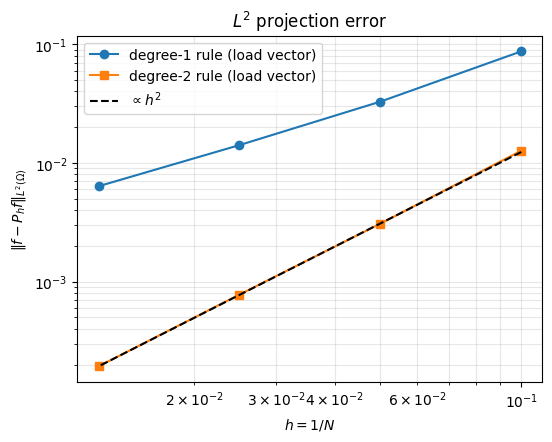

In [37]:
f = lambda x, y : np.sin(2*np.pi*x) * np.cos(np.pi*y)

N_vals = [10, 20, 40, 80]
h = np.array([1/N for N in N_vals])

xq4, wq4 = quadrature_rule(4)     # always the degree-4 rule for the error

errors = {}
for d in [1, 2]:                  # rule used for the load vector
    xq, wq = quadrature_rule(d)
    errors[d] = []
    for N in N_vals:
        P, C = mt.unitsquare_mesh(N)
        u = l2_projection(f, P, C, xq, wq)
        errors[d].append(compute_L2_error(f, u, P, C, xq4, wq4))


# Table
for d in [1, 2]:
    e = np.array(errors[d])
    eoc = np.log(e[:-1] / e[1:]) / np.log(2)
    conv_table = pd.DataFrame({
        "N": N_vals,
        "h": h,
        "L2_error": e,
        "EOC_L2": np.concatenate([[np.nan], eoc])
    })
    print(f"Load vector assembled with the degree-{d} rule:")
    display(conv_table)


# Log-log plot with an h^2 reference line through the last degree-2 error
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(h, errors[1], "o-", label="degree-1 rule (load vector)")
ax.loglog(h, errors[2], "s-", label="degree-2 rule (load vector)")
ax.loglog(h, errors[2][-1] * (h / h[-1])**2, "k--", label=r"$\propto h^2$")
ax.set_xlabel("$h = 1/N$")
ax.set_ylabel(r"$\|f - P_h f\|_{L^2(\Omega)}$")
ax.set_title(r"$L^2$ projection error")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()


#### Little discussion:

With the degree-2 rule we observe $\mathrm{EOC} \approx 2$, i.e. $\|f - P_h f\|_{L^2(\Omega)} = O(h^2)$, the optimal rate for $\mathbb{P}_1$ elements. With the degree-1 rule the EOC drops from about $1.4$ to $1.1$ and approaches $1$, because the quadrature error in the load vector is only first order and dominates for small $h$. This agrees with Task 1 b), where the differences decreased by factors of about 4 and 2, respectively.

The error computation needs a more accurate rule because it must measure $f - P_h f$ itself and not the quadrature error. If $|f - P_h f|^2$ were integrated with a low-degree rule, the quadrature error would be of the same size as the error we want to measure, and the computed convergence rate would be wrong. For example, the vertex rule would only see the error at the nodes and miss the error inside the triangles.